In [1]:
# Cell 1 — Import library
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Cell 2 — Load dataset
df = pd.read_csv("../data/processed/customer_support_tickets_clean.csv")

In [3]:
# Cell 3 — Data Quality check for resolution time

#1. Convert time to resolution and first response time to datetime
df["Time to Resolution"] = pd.to_datetime(
    df["Time to Resolution"],
    errors="coerce")

df["First Response Time"] = pd.to_datetime(
    df["First Response Time"],
    errors="coerce"
)

df["Resolution Duration"] = (
    df["Time to Resolution"]
    - df["First Response Time"]
)

#2. Number of missing values
print("Number of tickets with missing Resolution, first response time and time to resolution:")

print("Missing reslution name:",
    df["Resolution"].isna().sum()
)
print(
    "Missing First Response Time:",
    df["First Response Time"].isna().sum()
)

print(
    "Missing Time to Resolution:",
    df["Time to Resolution"].isna().sum()
)

#3. Show invalid negative resolution times
invalid = df[df["Resolution Duration"] < pd.Timedelta(0)]

print("Negative resolution durations:", len(invalid))

Number of tickets with missing Resolution, first response time and time to resolution:
Missing reslution name: 0
Missing First Response Time: 2819
Missing Time to Resolution: 5700
Negative resolution durations: 1365


In [4]:
# Cell 4 — Average resolution time by ticket type
avg_resolution_time = (
    df[df["Resolution Duration"] >= pd.Timedelta(0)]
    .groupby("Ticket Type")["Resolution Duration"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_resolution_time)

Ticket Type
Refund Request         0 days 08:07:04.144736842
Cancellation Request   0 days 07:41:35.094339622
Product Inquiry        0 days 07:40:33.852140077
Technical Issue        0 days 07:21:54.688524590
Billing Inquiry        0 days 07:00:36.923076923
Name: Resolution Duration, dtype: timedelta64[ns]


In [5]:
# Cell 5 — Identify the slowest and fastest ticket types
slowest_type = avg_resolution_time.idxmax()
fastest_type = avg_resolution_time.idxmin()

print(
    "Slowest ticket type:",
    slowest_type,
    "-",
    avg_resolution_time.max()
)

print(
    "Fastest ticket type:",
    fastest_type,
    "-",
    avg_resolution_time.min()
)

difference = (
    avg_resolution_time[slowest_type]
    - avg_resolution_time[fastest_type]
)

difference_hours = difference.total_seconds() / 3600

print(
    "Difference:",
    round(difference_hours, 2),
    "hours"
)

Slowest ticket type: Refund Request - 0 days 08:07:04.144736842
Fastest ticket type: Billing Inquiry - 0 days 07:00:36.923076923
Difference: 1.11 hours


In [6]:
# Cell 6 — Compare Resolution time with satisfaction
print("Average Resolution Time | Customer Satisfaction")
avg_satisfaction = (
    df.groupby("Ticket Type")["Customer Satisfaction Rating"]
      .mean()
)

comparison = pd.DataFrame({
    "Average Resolution Duration": avg_resolution_time,
    "Average Satisfaction": avg_satisfaction
})

comparison = comparison.sort_values(
    "Average Resolution Duration",
    ascending=False
)

print(comparison)

Average Resolution Time | Customer Satisfaction
                     Average Resolution Duration  Average Satisfaction
Ticket Type                                                           
Refund Request         0 days 08:07:04.144736842              2.934564
Cancellation Request   0 days 07:41:35.094339622              3.029070
Product Inquiry        0 days 07:40:33.852140077              3.016886
Technical Issue        0 days 07:21:54.688524590              2.958621
Billing Inquiry        0 days 07:00:36.923076923              3.027574


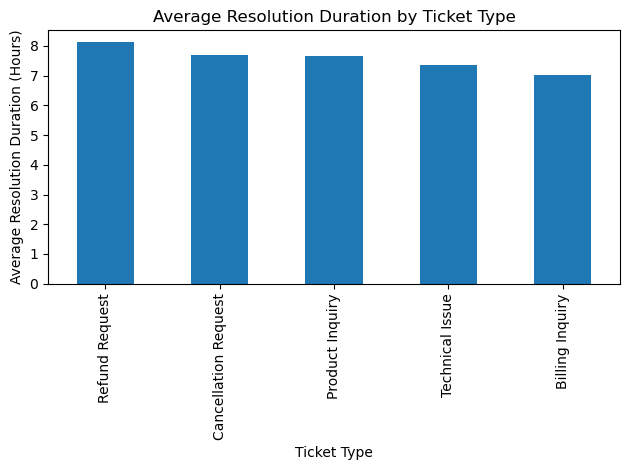

In [7]:
# Cell 7 — Visutalization


avg_resolution_hours = (
    avg_resolution_time.dt.total_seconds() / 3600
)

avg_resolution_hours.plot(
    kind="bar",
    title="Average Resolution Duration by Ticket Type"
)

plt.xlabel("Ticket Type")
plt.ylabel("Average Resolution Duration (Hours)")
plt.tight_layout()
plt.show()

## Business Observations

### Resolution Time Analysis

**Slowest-resolution category:** Refund request — approximately 8 hours 7 minutes

**Fastest-resolution category:** Billing inquiry — approximately 7 hours 1 minute

**Difference:** approximately 1.11 hours

### Key observations

- Refund requests have the longest average resolution duration among the
  five ticket types, at approximately 8 hours and 7 minutes.

- Billing inquiries have the shortest average resolution duration, at
  approximately 7 hours and 1 minute.

- Average resolution duration is relatively similar across all five
  ticket types. The difference between the slowest and fastest categories
  is approximately 1.11 hours.

- Cancellation requests and product inquiries have nearly identical
  average resolution durations, both at approximately 7 hours and
  40 minutes.

### Connection to customer satisfaction

- Refund requests have both the longest average resolution duration
  and the lowest average customer satisfaction rating (approximately 2.93).

- However, the other categories do not show a clear relationship between
  resolution duration and satisfaction. For example, Billing inquiries
  have the shortest average resolution duration, while their average
  satisfaction rating is approximately 3.03.

- These results suggest a possible relationship worth investigating for
  refund requests, but they do not establish that longer resolution times
  cause lower customer satisfaction.

### Business interpretation

Refund requests may deserve additional investigation because they combine
the longest observed average resolution duration with the lowest average
customer satisfaction rating.

However, the difference in average resolution duration across ticket types
is modest. A support manager should investigate additional factors such as
ticket priority, response delays, unresolved tickets, and the reasons why
refund requests require more time to resolve before making operational
changes.

### Limitations

- The analysis excludes records where Time to Resolution occurs before
  First Response Time because these produce invalid negative durations.

- Many tickets have missing First Response Time or Time to Resolution
  values, so the calculated averages represent only tickets with usable
  timestamp data.

- Average resolution duration can be influenced by unusually long tickets.

- This analysis identifies associations but does not establish that longer
  resolution duration causes lower customer satisfaction.